# 05 · Evaluation

**Goal:** judge the matching system the way a firm would before relying on it: each stage on its own, where it fails and why, whether every decision follows the rules, how it holds up on messier entries, and a fixed set of gates it has to pass.

Everything here uses VAL. TEST and the holdout file are scored once in notebook 06, with the same code (`src/evaluate.py`, `src/pipeline.py`) and the same gates, so the bar is set before the final results exist.

| Section | Question it answers |
|---|---|
| 3. Evaluation sets | What is each set for, and is it the same set next time? |
| 4. Stage by stage | How well does each step do on its own? |
| 5. Slices | Which kinds of entries does it handle well or badly? |
| 6. Error analysis | What goes wrong, how often, and why? |
| 7. Checks | Does every decision follow the rules, including its reason? |
| 8. Stress tests | What happens when entries are messier? |
| 9. Gates | Is it good enough on every axis, not just on average? |
| 10. Save | Did a later change make anything worse? |

## 1. Setup

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer

sys.path.insert(0, "../src")
from rules import ACTIONS, answer_key, score
from fuzzy import client_name_table
from pipeline import load_reference, decide_pairs, score_entries
from evaluate import (parse_metrics, pair_metrics, action_metrics, calibration_error, action_table, headline, slice_table,
                      add_failure_types, FAILURE_TYPES, check_decisions, stress_variants, changed_decisions,
                      check_gates, dataset_hash, compare_reports, matter_history, GATES, TRACKED)

In [2]:
DATA_PATH = Path("../data/synthetic_time_entries_v3.xlsx")
RESULTS_DIR = Path("../results")
SPLIT = "VAL"           # TEST and the holdout file are only scored in the final run
SETTING = "default"     # the chosen cutoffs from notebook 04
METHOD = f"classifier ({SETTING})"
SEED = 210


## 2. Load data

- **Decisions:** notebook 04's saved VAL decisions at the default setting, with their reasons.
- **Pairs:** VAL's pairs from notebook 02, scored again by the saved models so every candidate has its probability.
- **Entries:** as notebook 00 leaves them (emails parsed), for the stress tests.

The answer key is only used for scoring.

In [3]:
feature_config = json.loads((RESULTS_DIR / "02_config.json").read_text())
CLIENT_COL, MATTER_COL = feature_config["client_col"], feature_config["matter_col"]

matter_master = pd.read_excel(DATA_PATH, sheet_name="Matter Master", dtype=str)
pairs = pd.read_parquet(RESULTS_DIR / "02_pairs.parquet")
answers = answer_key(pairs)
entries = pd.read_parquet(RESULTS_DIR / "00_entries.parquet")
decisions = pd.read_csv(RESULTS_DIR / "04_decisions.csv", low_memory=False)
scored = decisions[(decisions["method"] == METHOD) & (decisions["split"] == SPLIT)].reset_index(drop=True)

split_ids = set(answers.loc[answers["split"] == SPLIT, "entry_id"])
split_pairs = pairs[pairs["entry_id"].isin(split_ids)].reset_index(drop=True)
split_entries = entries[entries["entry_id"].isin(split_ids)].reset_index(drop=True)
scored = scored.merge(entries[["entry_id", "source_format"]], on="entry_id")
rules_split = pd.read_csv(RESULTS_DIR / "03_decisions.csv", low_memory=False).query("split == @SPLIT")
rules_scored = score(rules_split[["entry_id", "shortlist", "action", "pred_cmid"]], answers)

encoder = SentenceTransformer(feature_config["embedding_model"])
ref = load_reference(DATA_PATH, RESULTS_DIR, encoder, SETTING)
split_pairs, top, _ = decide_pairs(split_pairs, ref)
valid_cmids = set(ref["matters"]["cmid"])

assert set(scored["entry_id"]) == split_ids == set(split_entries["entry_id"])
assert not decisions["split"].isin(["TEST", "HOLDOUT"]).any()
print(f"{SPLIT}: {len(scored)} entries | {len(split_pairs):,} pairs | setting: {SETTING}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

VAL: 601 entries | 61,903 pairs | setting: default


## 3. Evaluation sets

Each set has one job and isn't used for any other:

| Set | Job | Entries |
|---|---|---|
| TRAIN | fit models and tune settings (5 folds) | 2,802 |
| VAL | compare versions and choose settings; this notebook | 601 |
| TEST | one final score, after everything is frozen | 597 |
| Holdout file | conditions never seen: new phrasings, a timekeeper with no history, later dates | 800 |
| Stress set | VAL entries changed on purpose (section 8) | VAL × 9 |

**VAL is the golden set** every version is graded on. Each entry carries its type (clean, incomplete, messy, wrong CMID, multi-matter, new client, and so on), so results can be broken down by it. A short fingerprint of the entries and answer key is saved with the report, so a changed set can't pass as the same one.

In [4]:
golden = answers[answers["entry_id"].isin(split_ids)][["entry_id", "key_entry_category", "key_expected_action", "key_true_cmid", "key_secondary_cmid"]]
golden = golden.merge(entries[["entry_id", "source_format"]], on="entry_id")
fingerprints = {SPLIT: dataset_hash(golden, list(golden.columns)),
                "TEST ids": dataset_hash(answers[answers["split"] == "TEST"], ["entry_id"])}
print("Fingerprints:", fingerprints)
pd.crosstab(golden["key_entry_category"], golden["source_format"], margins=True)

Fingerprints: {'VAL': '1b45a83afbff', 'TEST ids': 'd21414339749'}


source_format,EMAIL,HANDWRITTEN,PDF,TYPED,All
key_entry_category,,,,,
AMBIGUOUS,9,5,6,18,38
CLEAN,0,29,29,90,148
CLOSED_OR_NOT_OPEN,0,2,2,6,10
INCOMPLETE,21,22,24,79,146
MESSY,20,28,25,54,127
MULTI_NAMED,6,2,4,11,23
MULTI_UNNAMED,2,3,0,9,14
NO_MATCH,9,7,2,19,37
WRONG_CMID_SILENT,0,6,4,22,32


- **Every entry type shows up in every format,** though some cells are small (10 to 40 entries), so one type in one format is noisy.
- **The TEST fingerprint only covers which entries are in it,** so notebook 06 can confirm it's the same untouched set.

## 4. Stage by stage

Each step can fail on its own, so measuring them separately shows which step a failure comes from.

### Extraction: emails

Emails are the one format with nothing in the CMID, client, or matter fields until notebook 00 parses them.

In [5]:
emails = split_entries[split_entries["source_format"] == "EMAIL"]
pd.Series(parse_metrics(emails, answers, client_name_table(matter_master, feature_config["acronym_skip"]))).round(3).to_frame(SPLIT)

,VAL
emails,67.000
hours_found,1.000
client_filled,0.701
right_client,0.655
wrong_client,0.052


- **Hours are found in every email.** The client field is filled for about 7 in 10, and it's the wrong client for about 1 in 20.
- **Emails that never name the client** can't be fixed here, so they lean on the narrative and timekeeper history like any incomplete entry.

### Step 1: the pair model

- **Top-1 / top-3:** share of entries whose right matter is ranked first or in the top three
- **Calibration error:** for each entry's top pick, the average gap between its probability and how often it's right (0 is perfect). That probability becomes the confidence a reviewer sees. It's measured on top picks only, since across all 103 candidates almost every pair is an easy no near 0, which makes any model look calibrated.

In [6]:
pd.Series(pair_metrics(split_pairs)).round(4).to_frame(SPLIT)

,VAL
entries,601.0000
top_1,0.9344
top_3,0.9894
mrr,0.9605
auroc,0.9963
pr_auc,0.9265
log_loss,0.0081
calibration_error,0.0375


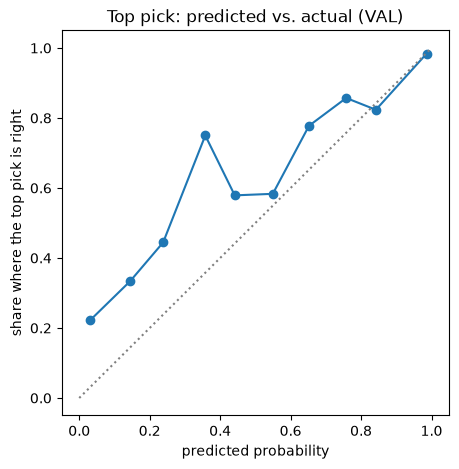

,predicted,actual,entries
prob,,,
"(-0.001, 0.1]",0.031,0.222,36
"(0.1, 0.2]",0.144,0.333,9
"(0.2, 0.3]",0.238,0.444,9
"(0.3, 0.4]",0.358,0.750,8
"(0.4, 0.5]",0.442,0.579,19
"(0.5, 0.6]",0.549,0.583,12
"(0.6, 0.7]",0.652,0.778,18
"(0.7, 0.8]",0.758,0.857,21
"(0.8, 0.9]",0.842,0.824,34


In [7]:
top_picks = split_pairs.loc[split_pairs.groupby("entry_id")["prob"].idxmax()]
bins = pd.cut(top_picks["prob"], np.linspace(0, 1, 11), include_lowest=True)
curve = top_picks.groupby(bins, observed=True).agg(predicted=("prob", "mean"), actual=("is_true_matter", "mean"), entries=("prob", "size"))
ax = curve.plot(x="predicted", y="actual", marker="o", legend=False, figsize=(5, 5), title=f"Top pick: predicted vs. actual ({SPLIT})")
ax.plot([0, 1], [0, 1], linestyle=":", color="gray")
ax.set(xlabel="predicted probability", ylabel="share where the top pick is right")
plt.show()
curve.round(3)

- The right matter is ranked first for 93% of VAL entries and in the top three for 99%.
- **High-confidence picks match their confidence:** above 0.8, where about 8 in 10 top picks land, the pick is right about as often as its probability says.
- **Low-confidence picks are under-confident:** below 0.5, the top pick is right more often than its probability says, because when every candidate scores low, the best one is still often right. That's the safe direction, and the calibration error (0.037) is under its gate line of 0.05 (section 9).

### Step 2: decisions

Precision and recall for each action. For actions that suggest a matter, `matter_right` is the share of calls where that matter is right.

In [8]:
action_table(scored).round(3)

,calls,expected,precision,recall,matter_right
AUTO_MATCH,423.0,453.0,0.877,0.819,0.979
FLAG_MISMATCH,22.0,36.0,0.455,0.278,0.773
NEEDS_REVIEW,91.0,38.0,0.088,0.211,0.582
MULTI_MATTER,46.0,37.0,0.652,0.811,0.457
NO_MATCH,19.0,37.0,0.947,0.486,NaN


In [9]:
pd.Series(headline(scored)).round(3).to_frame(SPLIT)

,VAL
entries,601.000
decided_precision,0.977
ci_low,0.964
ci_high,0.989
straight_through,0.735
review_share,0.151
matter_accuracy,0.870
action_accuracy,0.727
silent_errors,9.000
silent_rate,0.021


- **Auto-matches are what nobody checks,** so their matter accuracy is what counts: 98% are right.
- **`NEEDS_REVIEW` has low precision on purpose.** It's where uncertain entries go, so many entries the answer key would auto-match land there. That costs review time, not mistakes.
- **New-client calls are almost always right (95%),** but only about half of new clients get the call. The rest go to review, which is safe.
- **Flags suggest the right matter about 3 times in 4.**

### Metrics at a glance

Every number used to judge the system in one table, with standard machine-learning metrics next to the ones built for this task.

| Metric | What it means |
|---|---|
| **AUROC** | the chance a random positive scores higher than a random negative. 0.5 is a coin flip, 1.0 is perfect, and no cutoff is needed. |
| **PR-AUC** | how precise the model stays as it finds more of the positives. A random score gets the positive rate, so it drops when positives are rare. |
| **MRR** | 1 divided by the rank of the right matter, averaged. 1.0 means always first. |

**Reading them here:**
- **Step 1's AUROC is measured across all pairs,** where about 1 in 100 is right and most wrong ones are easy to rule out. So it reads close to 1 even when the top pick is wrong. Top-1 and MRR measure what a reviewer sees.
- **Step 2's action probabilities are each scored as a yes/no question,** with step 1's top probability scored the same way to show what step 2 adds.
- **End to end, the headline is decided precision** at a given straight-through rate.

In [10]:
step1 = pair_metrics(split_pairs)
step2 = action_metrics(top, answers)
end = headline(scored)

glance = pd.DataFrame([
    ("step 1", "top-1", step1["top_1"], "share of entries with the right matter ranked first"),
    ("step 1", "top-3", step1["top_3"], "share with the right matter in the top three (the review shortlist)"),
    ("step 1", "MRR", step1["mrr"], "1 / rank of the right matter, averaged (1 = always first)"),
    ("step 1", "AUROC", step1["auroc"], "right pairs score above wrong pairs, across all pairs"),
    ("step 1", "PR-AUC", step1["pr_auc"], "precision vs. recall across all pairs (random: about 0.01)"),
    ("step 1", "log loss", step1["log_loss"], "how far probabilities are from the 0/1 truth (lower is better)"),
    ("step 1", "calibration error", step1["calibration_error"], "top pick's probability vs. how often it's right (lower is better)"),
    ("step 2", "AUROC, P(auto)", step2.loc["auto", "auroc"], "separates entries safe to accept from the rest"),
    ("step 2", "AUROC, top probability alone", step2.loc["auto, top probability alone", "auroc"], "the same, with step 1's top probability only"),
    ("step 2", "AUROC, P(multi)", step2.loc["multi", "auroc"], "separates multi-matter entries from the rest"),
    ("step 2", "PR-AUC, P(multi)", step2.loc["multi", "pr_auc"], f"random: {step2.loc['multi', 'share']:.3f}"),
    ("step 2", "AUROC, P(no_match)", step2.loc["no_match", "auroc"], "separates new clients or matters from the rest"),
    ("step 2", "PR-AUC, P(no_match)", step2.loc["no_match", "pr_auc"], f"random: {step2.loc['no_match', 'share']:.3f}"),
    ("end to end", "decided precision", end["decided_precision"], "decisions made with no person that are right (the headline)"),
    ("end to end", "decided precision, low end", end["ci_low"], "low end of the 95% range, resampling timekeepers"),
    ("end to end", "straight-through rate", end["straight_through"], "entries decided with no person"),
    ("end to end", "review share", end["review_share"], "entries sent to NEEDS_REVIEW"),
    ("end to end", "silent errors per auto-match", end["silent_rate"], "auto-matches that go on the bill wrong (lower is better)"),
    ("end to end", "multi-matter caught", end["multi_caught"], "multi-matter entries that get the MULTI_MATTER call"),
    ("end to end", "new-client calls right", end["no_match_precision"], "NO_MATCH calls that really are new"),
    ("end to end", "right matter in review shortlist", end["shortlist_hit"], "reviewed entries with the right matter in the top three"),
    ("end to end", "matter accuracy", end["matter_accuracy"], "all entries whose suggested matter is right"),
], columns=["stage", "metric", SPLIT, "what it measures"]).set_index(["stage", "metric"])

with pd.option_context("display.max_colwidth", None):
    display(glance.round(3))

VAL  \
stage      metric                                    
step 1     top-1                             0.934   
           top-3                             0.989   
           MRR                               0.960   
           AUROC                             0.996   
           PR-AUC                            0.927   
           log loss                          0.008   
           calibration error                 0.037   
step 2     AUROC, P(auto)                    0.947   
           AUROC, top probability alone      0.848   
           AUROC, P(multi)                   0.979   
           PR-AUC, P(multi)                  0.825   
           AUROC, P(no_match)                0.988   
           PR-AUC, P(no_match)               0.874   
end to end decided precision                 0.977   
           decided precision, low end        0.964   
           straight-through rate             0.735   
           review share                      0.151   
           silent errors per auto-match      0.021   
           multi-matter caught               0.811   
           new-client calls right            0.947   
           right matter in review shortlist  0.791   
           matter accuracy                   0.870   

                                                                                                what it measures  
stage      metric                                                                                                 
step 1     top-1                                             share of entries with the right matter ranked first  
           top-3                             share with the right matter in the top three (the review shortlist)  
           MRR                                         1 / rank of the right matter, averaged (1 = always first)  
           AUROC                                           right pairs score above wrong pairs, across all pairs  
           PR-AUC                                     precision vs. recall across all pairs (random: about 0.01)  
           log loss                               how far probabilities are from the 0/1 truth (lower is better)  
           calibration error                   top pick's probability vs. how often it's right (lower is better)  
step 2     AUROC, P(auto)                                         separates entries safe to accept from the rest  
           AUROC, top probability alone                             the same, with step 1's top probability only  
           AUROC, P(multi)                                          separates multi-matter entries from the rest  
           PR-AUC, P(multi)                                                                        random: 0.062  
           AUROC, P(no_match)                                     separates new clients or matters from the rest  
           PR-AUC, P(no_match)                                                                     random: 0.062  
end to end decided precision                         decisions made with no person that are right (the headline)  
           decided precision, low end                           low end of the 95% range, resampling timekeepers  
           straight-through rate                                                  entries decided with no person  
           review share                                                             entries sent to NEEDS_REVIEW  
           silent errors per auto-match                 auto-matches that go on the bill wrong (lower is better)  
           multi-matter caught                               multi-matter entries that get the MULTI_MATTER call  
           new-client calls right                                             NO_MATCH calls that really are new  
           right matter in review shortlist              reviewed entries with the right matter in the top three  
           matter accuracy                                           all entries whose suggested matter i

- **Step 1 ranks well by every measure:** AUROC 0.996, PR-AUC 0.93 (vs. about 0.01 for a random score), and MRR 0.96. When the right matter isn't first, it's usually second.
- **AUROC alone would oversell step 1:** it's 0.996 while 1 entry in 15 still has the wrong matter on top. Top-1 and MRR are the step-1 numbers to report.
- **Step 2 earns its place:** P(auto) separates safe entries from the rest with an AUROC of 0.947, vs. 0.848 for step 1's top probability alone.
- **New clients and multi-matter entries are well separated** (AUROC 0.988 and 0.979), with PR-AUC far above their 6% base rate (0.87 and 0.83).

## 5. Slices

One overall number can hide a weak spot, so the same numbers are broken down by:
- **source format**
- **entry type**
- **billing history** (`matter_history`): whether the right matter has past entries. A matter that just opened has no past narratives or timekeeper hours to lean on, which firms run into all the time.

In [11]:
cols = ["entries", "decided_precision", "straight_through", "review_share", "silent_errors", "matter_accuracy"]
by_format = slice_table(scored, "source_format")
by_format[cols].round(3)

,entries,decided_precision,straight_through,review_share,silent_errors,matter_accuracy
EMAIL,67.0,0.944,0.537,0.328,1.0,0.731
HANDWRITTEN,109.0,0.988,0.743,0.174,1.0,0.927
PDF,99.0,0.962,0.798,0.101,3.0,0.889
TYPED,326.0,0.984,0.755,0.123,4.0,0.874


In [12]:
by_type = slice_table(scored, "key_entry_category")
by_type[cols].round(3)

,entries,decided_precision,straight_through,review_share,silent_errors,matter_accuracy
AMBIGUOUS,38.0,0.931,0.763,0.211,1.0,0.921
CLEAN,148.0,1.000,0.872,0.115,0.0,0.986
CLOSED_OR_NOT_OPEN,10.0,1.000,0.700,0.000,0.0,1.000
INCOMPLETE,146.0,1.000,0.870,0.110,0.0,0.973
MESSY,127.0,1.000,0.787,0.150,0.0,0.929
MULTI_NAMED,23.0,0.000,0.087,0.174,2.0,0.261
MULTI_UNNAMED,14.0,NaN,0.000,0.000,0.0,0.714
NO_MATCH,37.0,0.947,0.514,0.432,1.0,0.486
WRONG_CMID_SILENT,32.0,0.733,0.469,0.219,4.0,0.594
WRONG_CMID_TEXT,26.0,0.929,0.538,0.154,1.0,0.731


In [13]:
past_matters = answers.loc[(answers["split"] == "TRAIN") & (answers["key_true_cmid"] != "NONE"), "key_true_cmid"]
scored["matter_history"] = matter_history(scored, past_matters)
slice_table(scored, "matter_history", min_entries=1)[cols].round(3)

,entries,decided_precision,straight_through,review_share,silent_errors,matter_accuracy
new client or matter,37.0,0.947,0.514,0.432,1.0,0.486
new matter,3.0,NaN,0.000,1.000,0.0,0.667
seen before,561.0,0.979,0.754,0.128,8.0,0.897


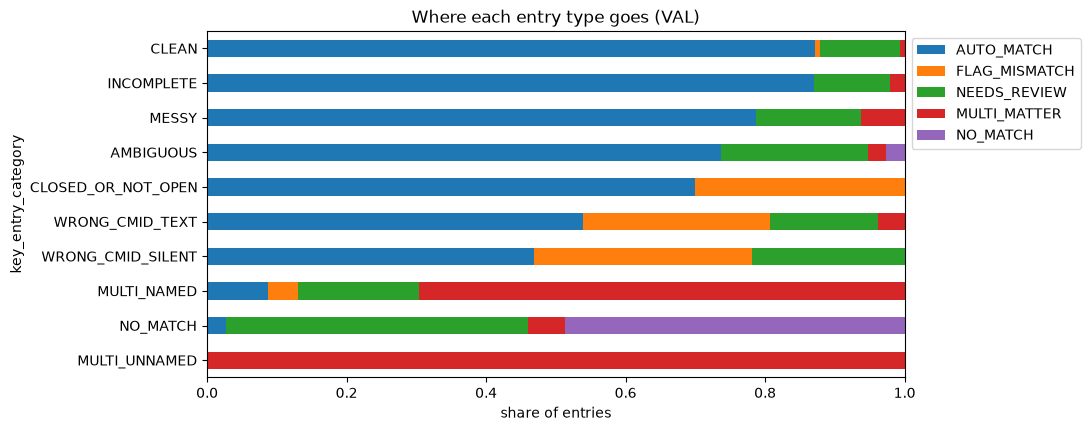

In [14]:
where = pd.crosstab(scored["key_entry_category"], scored["action"], normalize="index")[ACTIONS]
ax = where.sort_values("AUTO_MATCH").plot.barh(stacked=True, figsize=(9, 4.5), xlim=(0, 1), title=f"Where each entry type goes ({SPLIT})")
ax.set_xlabel("share of entries")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

### Typed-CMID corrections

Auto-matches whose reason says the typed CMID was corrected, by entry type, and how many went to the right matter.

In [15]:
corrected = scored[scored["reason_short"] == "Typed CMID corrected"]
corrections = corrected.groupby("key_entry_category")["matter_right"].agg(corrected="size", right_matter="sum")
corrections.loc["All"] = corrections.sum()
corrections

,corrected,right_matter
key_entry_category,,
CLOSED_OR_NOT_OPEN,7,7
MULTI_NAMED,1,0
WRONG_CMID_SILENT,12,11
WRONG_CMID_TEXT,13,13
All,33,31


- **By format:** typed and handwritten entries do best (98% to 99%), then PDFs (96%). Emails are decided automatically least often (54%) and have the lowest precision (94%), but they're the smallest slice, so one mistake moves them a lot.
- **By entry type:** clean, incomplete, messy, and closed-matter entries are right whenever they're decided automatically. The 9 silent errors are 5 wrong CMIDs, 2 named multi-matter entries, 1 ambiguous entry, and 1 new client accepted as a known matter.
- **By billing history:** entries on matters with past entries are decided automatically 75% of the time. The 3 entries on a matter with no past entries all go to review, so a new matter costs review time, not errors.
- **Typed-CMID corrections:** 31 of 33 go to the right matter, including all 13 wrong CMIDs the narrative contradicts and all 7 closed matters.
- **Wrong CMIDs nothing contradicts are the hardest** (32): 12 are corrected (11 right), 10 flagged, 7 sent to review, and 4 end up as silent errors.

## 6. Error analysis

Each decision gets the first failure type that applies (`add_failure_types`), ordered by cost. A silent error goes on the bill unchecked, while an extra review costs a reviewer a few seconds.

In [16]:
scored = add_failure_types(scored)
failures = scored["failure_type"].value_counts().rename("entries").to_frame()
failures["meaning"] = failures.index.map(FAILURE_TYPES)
failures

,entries,meaning
failure_type,,
"review, top pick right",53,"sent to review, but the top pick was right (ex..."
false multi-matter alarm,16,"called multi-matter, but covers one matter"
silent error,9,"accepted with no review, but the matter is wrong"
missed second matter,5,"covers two matters, but wasn't called multi-ma..."
wrong flag suggestion,4,"flagged, but the suggested matter is wrong"
"review, right matter not in shortlist",3,"sent to review, and the right matter isn't in ..."
wrong new-client call,1,"sent to intake as a new client or matter, but ..."


In [17]:
pd.crosstab(scored["failure_type"], scored["key_entry_category"])

key_entry_category,AMBIGUOUS,CLEAN,INCOMPLETE,MESSY,MULTI_NAMED,NO_MATCH,WRONG_CMID_SILENT,WRONG_CMID_TEXT
failure_type,,,,,,,,
false multi-matter alarm,1,1,3,8,0,2,0,1
missed second matter,0,0,0,0,5,0,0,0
"review, right matter not in shortlist",0,0,1,0,0,0,1,1
"review, top pick right",8,17,13,15,0,0,0,0
silent error,1,0,0,0,2,1,4,1
wrong flag suggestion,0,1,0,0,0,0,2,1
wrong new-client call,1,0,0,0,0,0,0,0


- **Most failures are extra work, not errors:** the biggest group (53) is entries sent to review whose top pick was already right, so the reviewer just confirms the first suggestion.
- **Silent errors are rare (9),** mostly wrong CMIDs that nothing in the entry contradicts.
- **Multi-matter mistakes go both ways:** 5 named multi-matter entries are missed, and 16 one-matter entries get a false alarm, half of them messy entries.
- **Wrong flag suggestions (4)** mostly come from wrong CMIDs: the flag is right, but the matter it suggests isn't.

In [18]:
cols = ["entry_id", "source_format", "key_entry_category", "action", "pred_cmid", "key_true_cmid", "reason_short"]
scored.loc[scored["failure_type"] == "silent error", cols]

,entry_id,source_format,key_entry_category,action,pred_cmid,key_true_cmid,reason_short
104,T-00621,TYPED,NO_MATCH,AUTO_MATCH,3455.002,NONE,You've billed this matter
105,T-00625,PDF,MULTI_NAMED,AUTO_MATCH,7222.002,7222.002,You've billed this matter
132,T-00814,EMAIL,AMBIGUOUS,AUTO_MATCH,9140.001,5524.001,You've billed this matter
216,T-01348,PDF,WRONG_CMID_SILENT,AUTO_MATCH,9140.001,2215.001,Typed CMID corrected
295,T-01867,TYPED,WRONG_CMID_SILENT,AUTO_MATCH,7215.005,7215.003,Typed CMID matches
488,T-03325,PDF,WRONG_CMID_SILENT,AUTO_MATCH,3120.001,4471.004,Typed CMID matches
516,T-03461,TYPED,WRONG_CMID_SILENT,AUTO_MATCH,8340.001,7215.003,You've billed this matter
529,T-03525,HANDWRITTEN,WRONG_CMID_TEXT,AUTO_MATCH,6110.002,1111.001,Typed CMID matches
531,T-03537,TYPED,MULTI_NAMED,AUTO_MATCH,7222.002,5531.001,Typed CMID corrected


## 7. Checks on every decision

Rules every decision should follow (`check_decisions`). They run on every output, so a broken rule is caught even when the overall numbers look fine.
- A suggested matter exists in Matter Master.
- An auto-matched matter was open on the work date.
- An auto-match that overrides a valid typed CMID says it corrected the CMID.
- A `NO_MATCH` call suggests no matter.
- Every decision has a short and a full reason.
- An auto-match's short reason is true for that entry ("Typed CMID matches" means it really does).
- The stated confidence (high, medium, low) matches the top pick's probability.
- A review shortlist has three different matters.

In [19]:
checks = check_decisions(scored, split_pairs, valid_cmids, CLIENT_COL, MATTER_COL, feature_config["phrase_min"])
checks

,entries_checked,violations,examples
check,,,
suggested matters exist in Matter Master,601,0,
auto-matched matter was open on the work date,601,0,
auto-match against a valid typed CMID says it corrected it,601,0,
NO_MATCH suggests no matter,601,0,
every decision has a reason,601,0,
auto-match reason is true for that entry,601,0,
stated confidence matches the probability,601,0,
review shortlist has 3 different matters,601,0,


- **No decision breaks a rule.** Reasons only cite clues that are really there, every corrected CMID says so, and the confidence label always matches the probability.

### Reproducibility

`src/pipeline.py` runs the saved models on entries it hasn't seen, which is what the final run and the stress tests use. Before trusting it, its decisions on the clean entries are compared with notebook 04's.

In [20]:
_, _, rerun = score_entries(split_entries, ref)
same = rerun.merge(scored[["entry_id", "action", "pred_cmid"]], on="entry_id", suffixes=("", "_04"))
same_action = same["action"] == same["action_04"]
print(f"Same decision as notebook 04: {same_action.sum()} of {len(same)} | same suggested matter: {(same['pred_cmid'].fillna('') == same['pred_cmid_04'].fillna('')).sum()} of {len(same)}")
same.loc[~same_action, ["entry_id", "action", "action_04"]]

Same decision as notebook 04: 601 of 601 | same suggested matter: 601 of 601


,entry_id,action,action_04


- **The pipeline matches notebook 04 on all 601 entries.** On another machine, an entry or two sitting right at a cutoff could tip from tiny rounding differences in the embeddings.

## 8. Stress tests

The synthetic entries are cleaner than real ones, so each VAL entry is changed on purpose and run through the whole pipeline again (`stress_variants`).

| Change | What it imitates |
|---|---|
| upper case narrative, extra spaces | formatting that shouldn't change anything |
| OCR noise | a scan misread (0 for O, l for 1, rn for m) on 10% of the letters it could hit |
| typo in client name or narrative | a slip while typing |
| CMID digits swapped | "6103.004" typed as "6013.004" |
| CMID or client left blank | missing fields |
| new timekeeper | someone with no billing history, like a lateral hire |

The first two should change nothing. The rest should make things harder, and a good system responds with more review, not more silent errors.

In [21]:
variants = stress_variants(split_entries, seed=SEED)
base = score(rerun, answers)
stress, changed = {"clean": headline(base)}, {"clean": 0.0}
for name, changed_entries in variants.items():
    _, _, out = score_entries(changed_entries, ref)
    stress[name] = headline(score(out, answers))
    changed[name] = changed_decisions(rerun, out)
stress = pd.DataFrame(stress).T.assign(changed=pd.Series(changed))
stress[["decided_precision", "ci_low", "straight_through", "review_share", "silent_errors", "matter_accuracy", "changed"]].round(3)

,decided_precision,ci_low,straight_through,review_share,silent_errors,matter_accuracy,changed
clean,0.977,0.964,0.735,0.151,9.0,0.870,0.000
"same, upper case narrative",0.977,0.964,0.735,0.151,9.0,0.870,0.000
"same, extra spaces",0.977,0.964,0.735,0.151,9.0,0.870,0.000
OCR noise (10% of letters),0.969,0.950,0.687,0.175,12.0,0.864,0.138
typo in client name,0.975,0.960,0.735,0.155,10.0,0.870,0.023
typo in narrative,0.974,0.956,0.692,0.181,10.0,0.867,0.103
CMID digits swapped,0.968,0.953,0.679,0.248,8.0,0.850,0.171
CMID left blank,0.963,0.945,0.674,0.213,14.0,0.814,0.185
client left blank,0.950,0.919,0.498,0.295,15.0,0.744,0.354
new timekeeper (no history),0.956,0.937,0.641,0.215,16.0,0.802,0.286


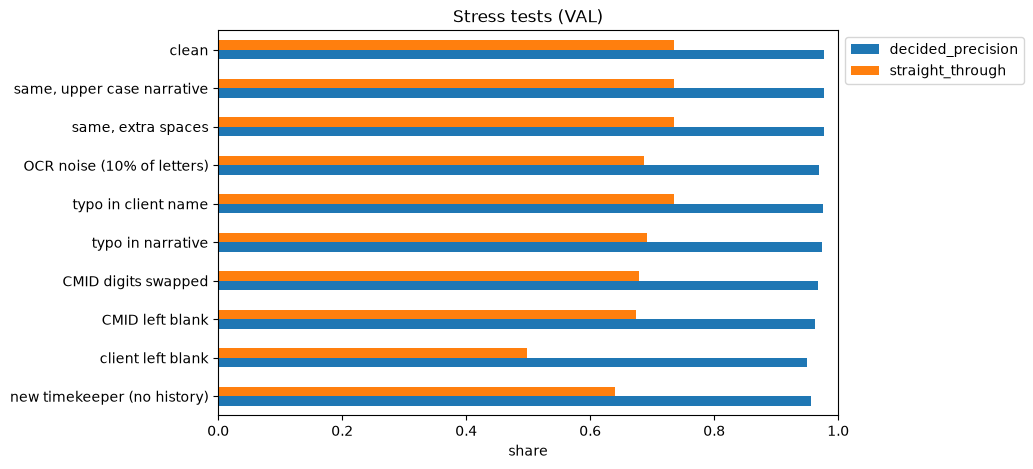

In [22]:
ax = stress.iloc[::-1][["decided_precision", "straight_through"]].plot.barh(figsize=(8, 5), xlim=(0, 1), title=f"Stress tests ({SPLIT})")
ax.set_xlabel("share")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

- **Formatting changes nothing,** as it should.
- **OCR noise, typos, and swapped digits** keep precision between 96.8% and 97.5%, mostly by sending more to review.
- **Swapped digits** land on a matter the narrative and history don't back up, so review rises from 15% to 25% with no extra silent errors.
- **A blank CMID** keeps precision at 96.3% but adds 5 silent errors (14 vs. 9).
- **A blank client** costs the most automation (50% decided with no person instead of 74%) and lands just under its tracked line (95.0%).
- **A new timekeeper** shows how much billing history helps: matter accuracy drops from 87% to 80%, and silent errors rise from 9 to 16.

## 9. Gates

Each gate is one axis that matters on its own, so a gain on one can't hide a loss on another. The lines live in `src/evaluate.py` and were set before the final run, so notebook 06 grades TEST and the holdout file against exactly the same ones.

| Source | Where the line comes from |
|---|---|
| Principle | anything else is a bug (a broken rule, a decision changed by formatting) |
| 97% target | follows from the chosen default setting |
| Baseline | the classifier has to beat the rules on the same entries |
| Team judgment | what a mistake costs a firm, to confirm with billing staff |

- **Blockers** have to pass for the system to be used.
- **Tracked** lines (stress tests and the weakest format) are reported every run but don't fail it. They show where the system is weakest, and the changes behind them are cruder than real ones.

In [23]:
rules_results = headline(rules_scored)
results = headline(scored) | pair_metrics(split_pairs) | {
    **{f"{label}_auroc": step2.loc[label, "auroc"] for label in ["auto", "multi", "no_match"]},
    "rules_decided_precision": rules_results["decided_precision"],
    "rules_silent_errors": rules_results["silent_errors"],
    "violations": int(checks["violations"].sum()),
    "formatting_changed": max(changed["same, upper case narrative"], changed["same, extra spaces"]),
    "stress_worst_precision": float(stress.drop(index="clean")["decided_precision"].min()),
    "format_worst_precision": float(by_format["decided_precision"].min()),
}
gates, tracked = check_gates(results, GATES), check_gates(results, TRACKED)
print(f"Blockers: {gates['passed'].sum()} of {len(gates)} passed | tracked: {tracked['passed'].sum()} of {len(tracked)} at or above their line")
pd.concat({"blocker": gates, "tracked": tracked})

Blockers: 9 of 10 passed | tracked: 1 of 2 at or above their line


value  \
        gate                                            
blocker decided precision, low end of range     0.964   
        silent errors per auto-match            0.021   
        decided precision above the rules       0.964   
        fewer silent errors than the rules      9.000   
        decisions breaking a check              0.000   
        decisions changed by formatting         0.000   
        new-client calls right                  0.947   
        multi-matter entries caught             0.811   
        right matter in review shortlist        0.791   
        top-pick calibration error              0.037   
tracked worst stress test, decided precision    0.950   
        worst source format, decided precision  0.944   

                                                                             rule  \
        gate                                                                        
blocker decided precision, low end of range                               >= 0.95   
        silent errors per auto-match                                      <= 0.03   
        decided precision above the rules       > rules_decided_precision (0.872)   
        fewer silent errors than the rules         < rules_silent_errors (36.000)   
        decisions breaking a check                                           <= 0   
        decisions changed by formatting                                      <= 0   
        new-client calls right                                             >= 0.9   
        multi-matter entries caught                                        >= 0.7   
        right matter in review shortlist                                   >= 0.8   
        top-pick calibration error                                        <= 0.05   
tracked worst stress test, decided precision                              >= 0.95   
        worst source format, decided precision                             >= 0.9   

                                                passed         source  \
        gate                                                            
blocker decided precision, low end of range       True     97% target   
        silent errors per auto-match              True     97% target   
        decided precision above the rules         True       baseline   
        fewer silent errors than the rules        True       baseline   
        decisions breaking a check                True      principle   
        decisions changed by formatting           True      principle   
        new-client calls right                    True  team judgment   
        multi-matter entries caught               True  team judgment   
        right matter in review shortlist         False  team judgment   
        top-pick calibration error                True  team judgment   
tracked worst stress test, decided precision     False     97% target   
        worst source format, decided precision    True  team judgment   

                                                                                              why  
        gate                                                                                       
blocker decided precision, low end of range        the 97% target, allowing for about 600 entries  
        silent errors per auto-match            at most 3 in 100 auto-matches go on the bill w...  
        decided precision above the rules             clearly better than the rules, not by noise  
        fewer silent errors than the rules                   the main reason to replace the rules  
        decisions breaking a check              every decision follows the checks in check_dec...  
        decisions changed by formatting                case and spacing shouldn't change anything  
        new-client calls right                         a wrong call sends a real client to intake  
        multi-matter entries caught              a missed second matter is misbilled or lost time  
        right matter in review shor

- **9 of 10 blockers pass.** The miss is the review shortlist: the right matter is in the top three for 79.1% of reviewed entries, against a line of 80%. With more entries decided automatically, the ones left for review are the harder ones. The line was a judgment call, so it's reported as a miss, not moved.
- **Calibration passes** (0.037 vs. 0.05).
- **The baseline gates pass clearly:** the low end of the precision range (96.4%) is well above the rules' 87.2%, and silent errors drop from 36 to 9.
- **One tracked line is missed:** a blank client lands just under 95%. The worst format (email, 94.4%) meets its 90% line.

## 10. Save

- `05_eval_report.json`: every number above, the gate results, the setting, and the set fingerprints. A later run is compared with it first, so a change that makes anything worse shows up right away.

In [24]:
report = {"split": SPLIT, "setting": SETTING, "fingerprints": fingerprints, "results": results,
          "gates": gates["passed"].to_dict(), "tracked": tracked["passed"].to_dict(), "stress": stress["decided_precision"].to_dict()}
report_path = RESULTS_DIR / "05_eval_report.json"
if report_path.exists():
    saved = json.loads(report_path.read_text())
    if saved["fingerprints"] == fingerprints and saved["setting"] == SETTING:
        keys = ["decided_precision", "straight_through", "silent_errors", "matter_accuracy", "top_1", "calibration_error"]
        print(compare_reports(results, saved["results"], keys).round(4))
report_path.write_text(json.dumps(report, indent=2, default=float))

print("Saved 05_eval_report.json")

                    saved     now  change
decided_precision  0.9774  0.9774     0.0
straight_through   0.7354  0.7354     0.0
silent_errors      9.0000  9.0000     0.0
matter_accuracy    0.8702  0.8702     0.0
top_1              0.9344  0.9344     0.0
calibration_error  0.0375  0.0375     0.0
Saved 05_eval_report.json


## 11. Findings

### Results
- **Decisions:** 97.7% of automatic decisions are right (range 96.4 to 98.9%) while about 3 in 4 entries are decided with no person.
- **Pair model:** the right matter is first for 93% of entries and in the top three for 99%, with an AUROC of 0.996 and MRR of 0.96.
- **Step 2 adds real signal:** P(auto) has an AUROC of 0.947 vs. 0.848 for step 1's top probability alone.
- **Typed-CMID corrections** catch wrong and closed-matter CMIDs, and 31 of 33 go to the right matter.
- **Checks:** every decision follows every rule, including that its reason is true.
- **Gates:** 9 of 10 blockers pass. The review shortlist misses by about a point.

### Where it struggles
- **Silent errors (9)** are mostly wrong CMIDs that nothing in the entry contradicts, plus 2 multi-matter entries.
- **Emails** trail other formats but are the smallest slice.
- **Messier input means more review, not more mistakes,** with precision between 95% and 97.5%. A new timekeeper adds the most silent errors.

### Tradeoffs
- **AUROC vs. top-1:** AUROC across all pairs looks near perfect because most wrong matters are easy to rule out. Top-1 and decided precision are what matter to a reviewer, so they're the headline.
- **More automation vs. a harder review list:** deciding more entries automatically leaves the hardest ones for review, which is why the shortlist gate slips.

### Limitations
- VAL has about 600 entries, so a slice of 30 or 70 moves several points with one mistake. The ranges say more than the exact numbers.
- The stress tests use simple rules. Real OCR errors and typing habits are messier, so these are a floor on how hard real data is.
- Everything is synthetic, since firms can't share real time entries.

### Next steps
- Confirm the judgment-call gate lines with billing staff, especially the review shortlist. Typed-CMID corrections were confirmed with a legal assistant, as long as the reason says the CMID was corrected.
- Run TEST and the holdout file once through the same pipeline, checks, and gates (notebook 06).